In [38]:
!pip install yfinance

In [39]:
# Import the libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

====== Complete Stock Analyzer =======


Enter the stock symbol (or Q to Quit): MRF.NS


Invalid Symbol or Network error



Enter the stock symbol (or Q to Quit): ADANIPORTS.NS



 Company :Adani Ports and Special Economic Zone Limited
 Current Price: 1828.1



[*********************100%***********************]  1 of 1 completed


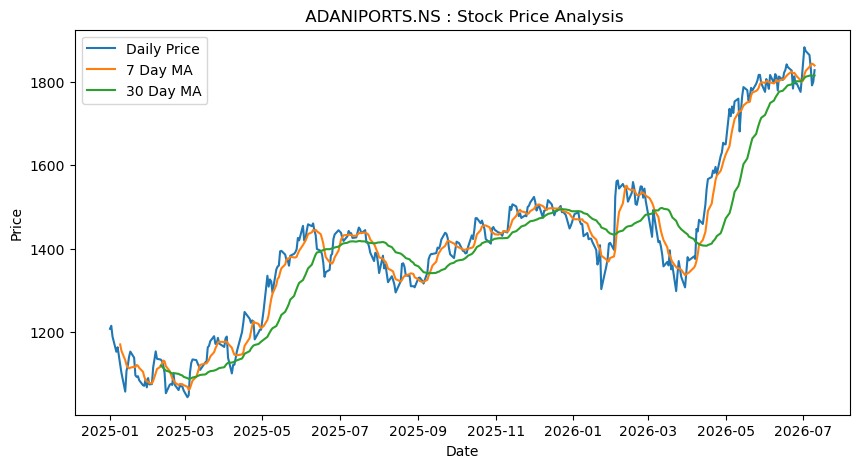

Enter the stock symbol (or Q to Quit): IRCTC


HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: IRCTC"}}}



 Company :N/A
 Current Price: None



HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: IRCTC"}}}
$IRCTC: possibly delisted; no timezone found
[*********************100%***********************]  1 of 1 completed

1 Failed download:
['IRCTC']: possibly delisted; no timezone found


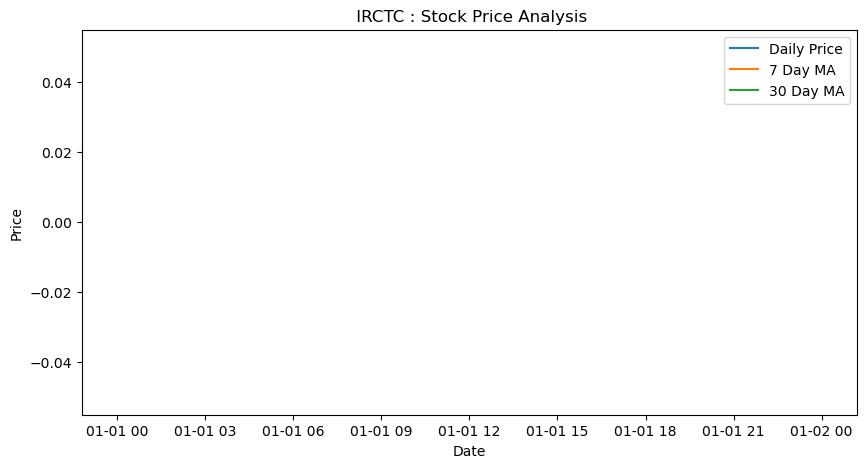

In [ ]:
print("====== Complete Stock Analyzer =======")

while True:

    symbol = input("Enter the stock symbol (or Q to Quit):").upper()

    if symbol == "Q":
        print("Exiting Program...")
        break

    try:
        stock = yf.Ticker(symbol)
        info = stock.info

        name = info.get("longName","N/A")
        price = info.get("currentPrice")
        prev_close = info.get("previousClose")
        currency = info.get("currency","USD")

        print("\n ==========================")
        print(f" Company :{name}")
        print(f" Current Price: {price}")
        print("\n ==========================")


        #Download the historical data

        df = yf.download(symbol,start= "2025-01-01",end="2026-07-12",interval="1d")

        # Moving average 

        df["7_day_MA"] = df["Close"].rolling(window=7).mean()
        df["30_day_MA"] = df["Close"].rolling(window=30).mean()

        # Plot the graph

        plt.figure(figsize=(10,5))
        plt.plot(df["Close"],label="Daily Price")
        plt.plot(df["7_day_MA"],label="7 Day MA")
        plt.plot(df["30_day_MA"], label="30 Day MA")
        plt.title(f" {symbol} : Stock Price Analysis")
        plt.xlabel("Date")
        plt.ylabel("Price")
        plt.legend()
        plt.show()

    except Exception as e:
        print("Invalid Symbol or Network error\n")
        